In [1]:
!pip -q install torch torchvision opencv-python pillow matplotlib numpy scikit-image scipy huggingface_hub

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

from google.colab import files

In [3]:
print("Upload the BEFORE image")
uploaded_before = files.upload()

print("\nUpload the AFTER image")
uploaded_after = files.upload()

before_path = list(uploaded_before.keys())[0]
after_path = list(uploaded_after.keys())[0]

print("Before:", before_path)
print("After :", after_path)

Upload the BEFORE image


Saving WhatsApp Image 2026-10-16 at 23.18.42 (1).jpeg to WhatsApp Image 2026-10-16 at 23.18.42 (1).jpeg

Upload the AFTER image


Saving WhatsApp Image 2026-10-16 at 23.18.42.jpeg to WhatsApp Image 2026-10-16 at 23.18.42.jpeg
Before: WhatsApp Image 2026-10-16 at 23.18.42 (1).jpeg
After : WhatsApp Image 2026-10-16 at 23.18.42.jpeg


In [4]:
IMG_SIZE = 256

def load_and_preprocess(path, size=IMG_SIZE):

    img = Image.open(path).convert("RGB")

    original_size = img.size

    # Resize automatically
    img_resized = img.resize((size, size), Image.Resampling.BILINEAR)

    # Convert to numpy
    img_np = np.array(img_resized).astype(np.float32) / 255.0

    # Normalize for ImageNet pretrained encoder
    tensor = transforms.ToTensor()(img_resized)

    normalize = transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

    tensor = normalize(tensor)

    return img, img_resized, img_np, tensor.unsqueeze(0), original_size


before_original, before_resized, before_np, before_tensor, before_size = \
    load_and_preprocess(before_path)

after_original, after_resized, after_np, after_tensor, after_size = \
    load_and_preprocess(after_path)

print("Before original size:", before_size)
print("After original size :", after_size)

print("Model input:", before_tensor.shape)

Before original size: (1600, 1201)
After original size : (1600, 1201)
Model input: torch.Size([1, 3, 256, 256])


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using:", device)

# Pretrained ResNet18
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Remove classification layer
encoder = nn.Sequential(*list(resnet.children())[:-2])

encoder = encoder.to(device)
encoder.eval()

Using: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Con

In [6]:
with torch.no_grad():

    before_features = encoder(
        before_tensor.to(device)
    )

    after_features = encoder(
        after_tensor.to(device)
    )

print("Feature shape:", before_features.shape)

Feature shape: torch.Size([1, 512, 8, 8])


In [7]:
# Absolute feature difference
feature_difference = torch.abs(
    before_features - after_features
)

# Collapse channels
change_map = feature_difference.mean(dim=1)

# Resize back to 256x256
change_map = F.interpolate(
    change_map.unsqueeze(1),
    size=(IMG_SIZE, IMG_SIZE),
    mode="bilinear",
    align_corners=False
)

change_map = change_map.squeeze().cpu().numpy()

# Normalize 0-1
change_map = (
    change_map - change_map.min()
) / (
    change_map.max() - change_map.min() + 1e-8
)

print(
    "Change score range:",
    change_map.min(),
    "→",
    change_map.max()
)

Change score range: 0.0 → 1.0


In [8]:
THRESHOLD = 0.55

change_mask = change_map > THRESHOLD

print(
    "Changed pixels:",
    change_mask.sum()
)

print(
    "Changed area:",
    100 * change_mask.mean(),
    "%"
)

Changed pixels: 22881
Changed area: 34.91363525390625 %


In [9]:
# Connected components
labeled, num_features = ndimage.label(change_mask)

component_sizes = np.bincount(labeled.ravel())

MIN_REGION_SIZE = 30

clean_mask = change_mask.copy()

for component_id in range(1, num_features + 1):

    if component_sizes[component_id] < MIN_REGION_SIZE:
        clean_mask[labeled == component_id] = False

print("Regions detected:", num_features)

Regions detected: 1


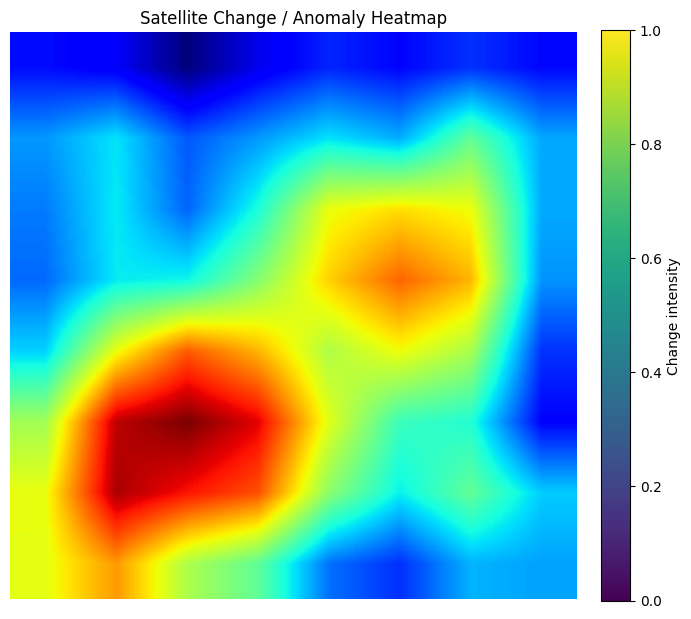

In [10]:
heatmap = plt.cm.jet(change_map)[:, :, :3]

heatmap_uint8 = (
    heatmap * 255
).astype(np.uint8)

plt.figure(figsize=(8, 8))

plt.imshow(heatmap)

plt.title("Satellite Change / Anomaly Heatmap")

plt.axis("off")

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Change intensity"
)

plt.show()

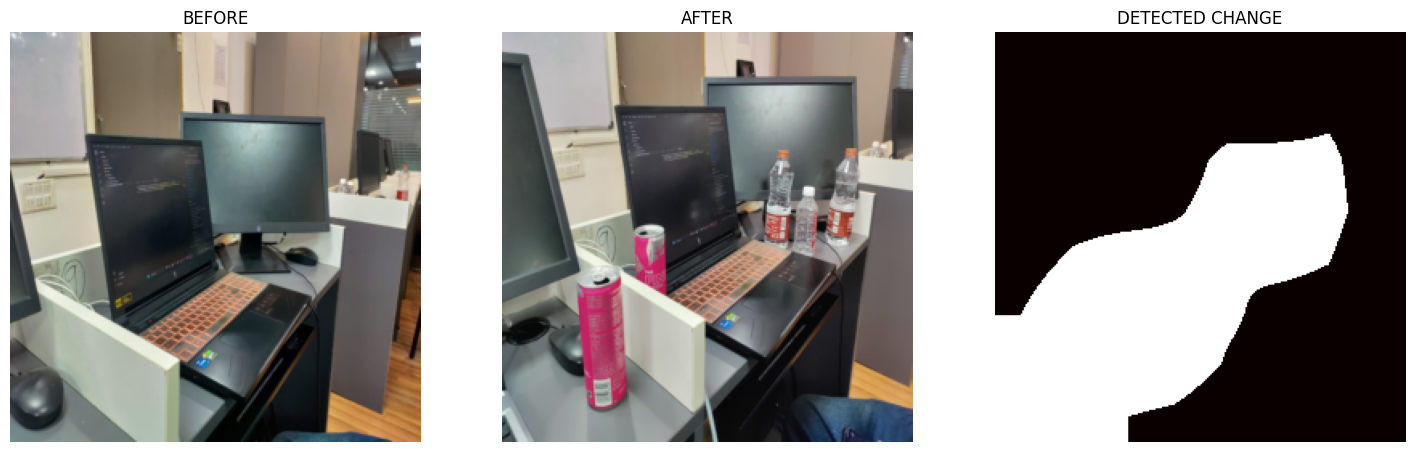

In [11]:
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)

plt.imshow(before_resized)

plt.title("BEFORE")

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(after_resized)

plt.title("AFTER")

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(clean_mask, cmap="hot")

plt.title("DETECTED CHANGE")

plt.axis("off")

plt.show()

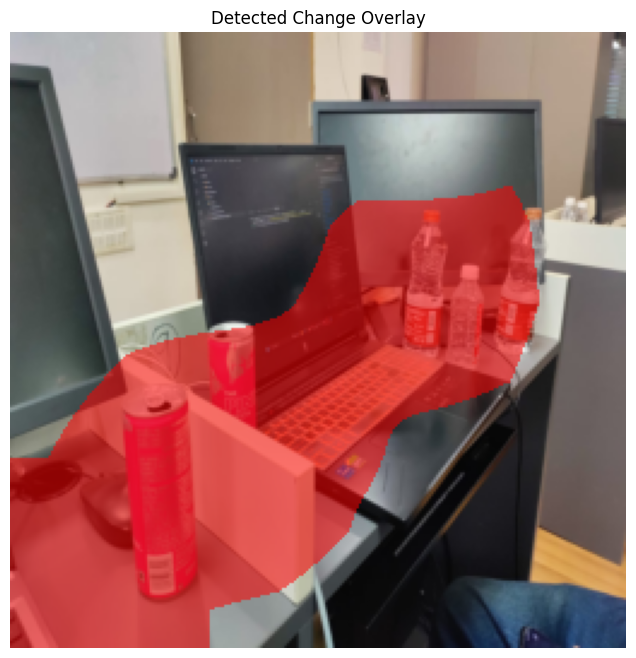

In [12]:
overlay = after_np.copy()

# Red highlight for detected changes
overlay[clean_mask] = [
    1.0,
    0.0,
    0.0
]

# Blend original and highlighted image
alpha = 0.55

overlay_result = (
    (1 - alpha) * after_np +
    alpha * overlay
)

plt.figure(figsize=(8, 8))

plt.imshow(overlay_result)

plt.title("Detected Change Overlay")

plt.axis("off")

plt.show()

In [13]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    clean_mask.astype(np.uint8),
    connectivity=8
)

region_info = []

for i in range(1, num_labels):

    x, y, w, h, area = stats[i]

    if area < MIN_REGION_SIZE:
        continue

    cx, cy = centroids[i]

    region_info.append({
        "id": i,
        "x": x,
        "y": y,
        "width": w,
        "height": h,
        "area_pixels": area,
        "center_x": cx,
        "center_y": cy
    })

region_info = sorted(
    region_info,
    key=lambda x: x["area_pixels"],
    reverse=True
)

print("Top detected regions:")

for region in region_info[:10]:

    print(
        f"Region {region['id']}: "
        f"{region['area_pixels']} pixels "
        f"at ({region['center_x']:.0f}, "
        f"{region['center_y']:.0f})"
    )

Top detected regions:
Region 1: 22881 pixels at (105, 164)


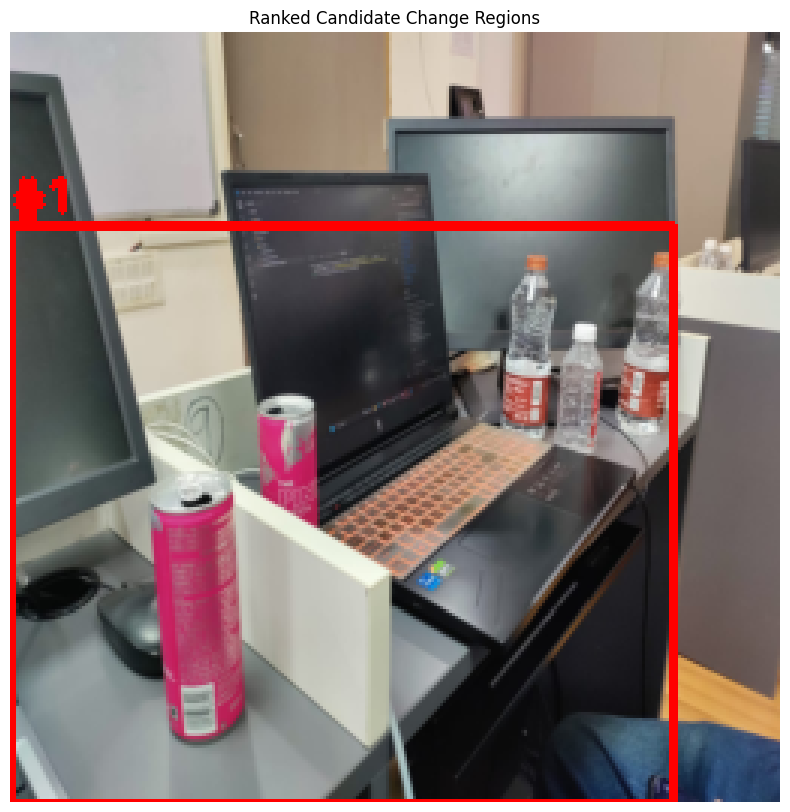

In [14]:
display_image = (
    after_np * 255
).astype(np.uint8)

display_image = cv2.cvtColor(
    display_image,
    cv2.COLOR_RGB2BGR
)

for rank, region in enumerate(region_info[:10], start=1):

    x = region["x"]
    y = region["y"]
    w = region["width"]
    h = region["height"]

    cv2.rectangle(
        display_image,
        (x, y),
        (x + w, y + h),
        (0, 0, 255),
        2
    )

    cv2.putText(
        display_image,
        f"#{rank}",
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        2
    )

display_image = cv2.cvtColor(
    display_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 10))

plt.imshow(display_image)

plt.title("Ranked Candidate Change Regions")

plt.axis("off")

plt.show()

In [15]:
total_pixels = clean_mask.size
changed_pixels = clean_mask.sum()

changed_percentage = (
    changed_pixels / total_pixels
) * 100

print("=" * 60)
print("EDGECHANGE REPORT")
print("=" * 60)

print(f"Image size: {IMG_SIZE} × {IMG_SIZE}")
print(f"Threshold: {THRESHOLD}")
print(f"Minimum region size: {MIN_REGION_SIZE} pixels")

print()

print(
    f"Changed pixels: "
    f"{changed_pixels:,} / {total_pixels:,}"
)

print(
    f"Estimated changed percentage: "
    f"{changed_percentage:.2f}%"
)

print(
    f"Candidate regions: "
    f"{len(region_info)}"
)

print()

print("IMPORTANT:")
print(
    "Detected regions represent candidate surface changes."
)

print(
    "They do NOT prove a specific activity such as "
    "illegal mining."
)

print(
    "Human validation is required."
)

print("=" * 60)

EDGECHANGE REPORT
Image size: 256 × 256
Threshold: 0.55
Minimum region size: 30 pixels

Changed pixels: 22,881 / 65,536
Estimated changed percentage: 34.91%
Candidate regions: 1

IMPORTANT:
Detected regions represent candidate surface changes.
They do NOT prove a specific activity such as illegal mining.
Human validation is required.


In [16]:
import torch
import torchvision
import torch.nn as nn
from torchvision import models

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

resnet = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

encoder = nn.Sequential(
    *list(resnet.children())[:-2]
)

encoder.eval()

dummy_input = torch.randn(1, 3, 256, 256)

with torch.no_grad():
    features = encoder(dummy_input)

print("Feature shape:", features.shape)

PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
Feature shape: torch.Size([1, 512, 8, 8])
